In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
%pip install ipympl
%matplotlib widget

Note: you may need to restart the kernel to use updated packages.


In [ ]:
#cleaned data set loaded
df=pd.read_csv('../data/cleaned_data.csv')

In [3]:
df.shape

(7032, 31)

In [4]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,1,0,0,0,2,1,1,53.85,108.15,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [5]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'Churn', 'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No internet service', 'StreamingMovies_Yes',
       'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='object')

In [6]:
#jo columns segmentation k liye valuable nhi the une drop kr diya
segmentation_df = df.drop(columns=['Churn', 'gender', 'SeniorCitizen', 'Partner', 'Dependents'])

In [7]:
segmentation_df.shape

(7032, 26)

In [8]:
segmentation_df.columns

Index(['tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges',
       'TotalCharges', 'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No internet service', 'StreamingMovies_Yes',
       'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='object')

In [9]:
#features ko scale kia taki koi bhi column bias na kre model ko high varience k whja se
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
scaled_data=scaler.fit_transform(segmentation_df)


In [ ]:
import pickle 
pickle.dump(scaler,open('../picklefiles/scale.pkl','wb'))

In [12]:
#oca (principal component analysis) feature reduction k liye abhi humne actually m feature ko reduct nhi kia
#abhi sb m pca kr k check kra konsa feature kitna varience carry krta h taki decide kr ske kitne feature max varience(data information)
#carry krte hai
from sklearn.decomposition import PCA
pca=PCA(n_components=None)
pca.fit(scaled_data)

PCA()

In [13]:
#ye bta raha h kons afeature kitna varience carry krta hai
pca.explained_variance_ratio_

array([3.80025991e-01, 1.28970843e-01, 1.01673153e-01, 5.22480361e-02,
       4.75150698e-02, 4.42447379e-02, 3.48160274e-02, 3.16548967e-02,
       2.86169884e-02, 2.60144830e-02, 2.37933380e-02, 2.33544602e-02,
       1.99050084e-02, 1.79113744e-02, 1.71764778e-02, 1.06658596e-02,
       9.16126993e-03, 2.21747399e-03, 3.45118188e-05, 9.65342226e-18,
       4.62894518e-18, 3.11154193e-18, 4.90496905e-19, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00])

In [14]:
#humne feature ki pc(principal componenet)ko sum kia or ab check krenge konse index tk max varience carry ho raha hai
import numpy as np
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
print(cumulative_variance)

[0.38002599 0.50899683 0.61066999 0.66291802 0.71043309 0.75467783
 0.78949386 0.82114875 0.84976574 0.87578023 0.89957356 0.92292802
 0.94283303 0.96074441 0.97792088 0.98858674 0.99774801 0.99996549
 1.         1.         1.         1.         1.         1.
 1.         1.        ]


In [ ]:
# hume clustring krni h toh 11th index jaha 92% info carry ho rhi h choose krenge 
# kuki clustring m jitna dimension km ho utna bdiya reta h cleaner cluster k liye

In [15]:
#new pca with components 11
pca_final=PCA(n_components=11)

In [16]:
pca_data=pca_final.fit_transform(scaled_data)

In [ ]:
pickle.dump(pca_final,open('../picklefiles/pca.pkl','wb'))

In [18]:
pca_data.shape

(7032, 11)

In [19]:
from sklearn.cluster import KMeans

In [20]:
#elbow method wcss(within cluster sum of square) ye pta krne m madada krta hai konsa k use kre
# yeah pr humne 1 10 cluster try kre or jaha hume elbow cut dikha jo k use kra
wcss=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k,random_state=42)
    kmeans.fit(pca_data)
    wcss.append(kmeans.inertia_)



In [21]:
wcss

[164470.8338242687,
 99517.79776003807,
 81503.8826193151,
 66735.71725419369,
 61596.71737090081,
 57045.45852763641,
 54271.652544055374,
 51875.1883272133,
 50220.786410751505,
 47541.02227723578]

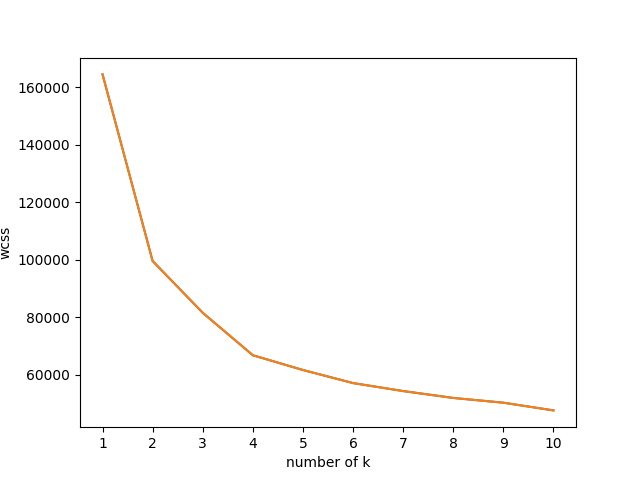

In [23]:
plt.plot(range(1,11),wcss)
plt.xticks(range(1,11))
plt.xlabel('number of k')
plt.ylabel('wcss')
plt.show()
#elbow cut 4 mai hai

In [24]:
#silhouette score bhi same kam krta h wcss jesa pr ye data point apne cluster k points s kitna pass or dusre cluster s kitan dur h dono ko calculate krta hai
#isme humne 2 se 6 k use kre 
from sklearn.metrics import silhouette_score
sc=[]
for k in range(2,7):
    kmeans=KMeans(n_clusters=k,random_state=42)
    labels=kmeans.fit_predict(pca_data)
    score = silhouette_score(pca_data, labels)
    sc.append(score)


In [25]:
sc
# elbow method wcs smai 4 cluster best baatye or isme 2 pr konsa lena h ye proejct k goal decide krega
# hamre project k business goal h costumer ko alag alag segment m dikhana pr 2 jayeda reliable nhi hpga 4 different segment ho
#jaise at low risk, high risk, old customer ,new customer type

[np.float64(0.4232918071585541),
 np.float64(0.2821860297399078),
 np.float64(0.31665423859135355),
 np.float64(0.27288821198157415),
 np.float64(0.2717150795418672)]

In [26]:
kmeans_final=KMeans(n_clusters=4,random_state=42)

In [27]:
cluster_labels=kmeans_final.fit_predict(pca_data)

In [ ]:
pickle.dump(kmeans_final,open('../picklefiles/kmeans.pkl','wb'))

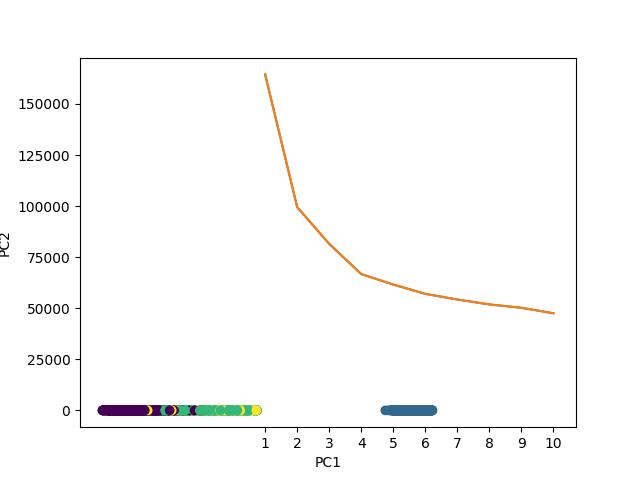

In [29]:
plt.scatter(pca_data[:,0],pca_data[:,1],c=cluster_labels)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

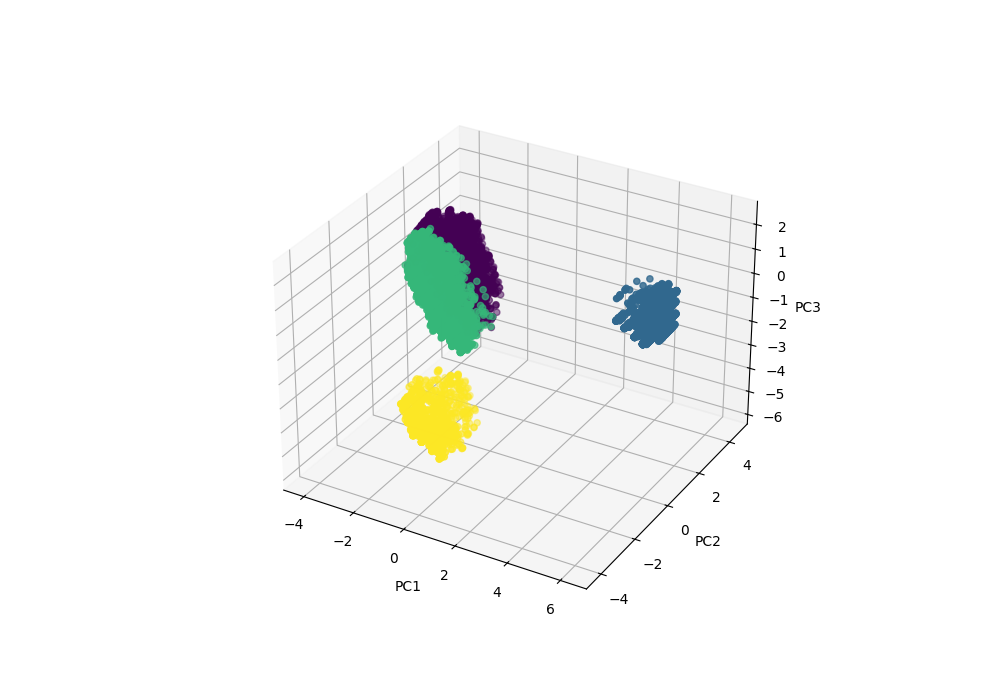

In [30]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(pca_data[:, 0], pca_data[:, 1], pca_data[:, 2], c=cluster_labels)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')

plt.show()

In [31]:
#new segment column add kra dataset mai
df['Segment']=cluster_labels

In [32]:
df['Segment'].shape

(7032,)

In [33]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Segment
0,0,0,1,0,1,0,1,29.85,29.85,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,3
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,2
2,1,0,0,0,2,1,1,53.85,108.15,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,3
4,0,0,0,0,2,1,1,70.70,151.65,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2


In [34]:
df['Segment'].value_counts()

Segment
2    2795
0    2037
1    1520
3     680
Name: count, dtype: int64

In [35]:
df.groupby('Segment').mean()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
Segment,,,,,,,,,,,,,,,,,,,,,
0,0.499264,0.190967,0.675503,0.345115,56.363279,1.0,0.679431,92.332744,5222.328130,0.147766,...,0.607266,0.0,0.738832,0.0,0.743741,0.352970,0.426608,0.340697,0.256750,0.085420
1,0.509211,0.034211,0.482237,0.419079,30.667763,1.0,0.292763,21.076283,665.220329,0.074342,...,0.000000,1.0,0.000000,1.0,0.000000,0.238816,0.416447,0.217763,0.080263,0.483553
2,0.503399,0.213596,0.348837,0.198569,16.070841,1.0,0.698748,74.056655,1211.755438,0.459750,...,0.184615,0.0,0.327370,0.0,0.328444,0.087657,0.008587,0.122719,0.534526,0.191771
3,0.516176,0.152941,0.454412,0.300000,31.830882,0.0,0.567647,41.992500,1500.433750,0.250000,...,0.422059,0.0,0.416176,0.0,0.438235,0.213235,0.233824,0.225000,0.332353,0.233824


## Segmentation — Conclusion

Using PCA (11 components, ~90% variance retained) and K-Means (k=4, chosen via Elbow Method + Silhouette Score), customers were grouped into 4 segments:

- **Segment 0 — Loyal High-Value**: Long tenure, highest spend, lowest churn (~15%). Core customer base to retain.
- **Segment 1 — Budget, Phone-Only**: Lowest spend, no internet service, most stable (~7% churn).
- **Segment 2 — New, At-Risk**: Largest segment (~40%), shortest tenure, highest churn (~46%). Top priority for retention.
- **Segment 3 — Internet-Only, No Phone**: Structurally distinct niche group, moderate churn (~25%).

**Key takeaway**: Segment 2 is both the largest and highest-risk group — retention efforts should focus here first. These segment labels will later be combined with churn prediction output to generate a readable risk category per customer.

In [ ]:
df.to_csv('../data/segmented_data.csv',index=False)